(lyzenga-recalc)=
# Impedance Match For Jackson and Ahrens 1979 Data



In [62]:
#@title Double-click to collapse code
%matplotlib inline
import os
from os.path import exists

# Collect files needed to run this notebook in the cloud (e.g., Google CoLab)
use_local_files = True # prefer local files than GitHub repo (change to false to refresh from repo)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os
from os.path import exists

# Impedance Match Calculation classes and functions
import IM_module as IM # classes and functions for this impedance match notebook
from scipy import linalg
from copy import deepcopy

# customized python classes and functions for EOS data
import hpeos_module as hp # holds shock Hugoniot python class
import pickle

# date & time used for unique output file name below
from datetime import datetime
print("Date and time: ", datetime.now())


Date and time:  2025-05-05 10:36:20.809990


## Choose load pickle file or re-run Monte Carlo Impedance Match

When compiled for the Jupyterbook, using N=50. 

N=1000 run used for error bars and plots at the bottom.


In [63]:
# Run the MC again
RUNMC = True
# Load the pickle file; do not run; set to False to compile the Jupyterbook
#RUNMC = False

# set number of IM calcs
#N=50
N=1000


## Load the material database

In [64]:
# load the materials data table; change matfilename if not using default
matdata, imat = IM.ReadMaterials(matfilename='materials-data.csv')

display(matdata)

,Material,Density(kg/m3),rho0_err,c0(m/s),c0_err,s1,s1_err,s2(s/m),s2_err,d(s/m),d_err,g0,g0_err,q,q_err,up_low(m/s),up_high(m/s),IHED_id,Date,Notes
0,Tantalum2023,16649.0,-1,3289.00000,0.025,1.313000,0.011,0.000000,-1.0,0.000000,0.0,1.62,-1,1.00,-1,0.0,-1.0,75,2023-09-10,AGU Reference Shelf+Katahara et al. 1979+Cohen...
1,Steel304-l2,7870.0,-1,4580.00000,-1.000,1.490000,-1.000,0.000000,-1.0,0.000000,0.0,2.20,-1,1.00,-1,170.0,3607.0,347,2023-09-04,STS refit Duffy+IHED RECOMMENDED
2,Fused-qtz-stv,2204.0,-1,1382.81770,-1.000,1.535125,-1.000,0.000000,0.0,0.000000,0.0,0.65,-1,1.00,-1,2800.0,4000.0,143,2023-09-04,STS fit to stv region RECOMMENDED
3,qtz-CaCl2-region,2650.0,-1,1797.25088,-1.000,1.688354,-1.000,0.000000,-1.0,0.000000,0.0,1.00,-1,1.00,-1,0.0,-1.0,174,2023-09-04,Stewart fit CaCl2 region RECOMMENDED
4,Aluminium 6061,2683.0,-1,5349.00000,-1.000,1.338000,-1.000,0.000000,-1.0,0.000000,0.0,1.00,-1,1.00,-1,-1.0,-1.0,324,2022-11-11,Duffy & Ahrens 1998 NEED TO ADD Z data
5,Steel 304,7870.0,-1,4580.00000,-1.000,1.490000,-1.000,0.000000,-1.0,0.000000,0.0,2.20,-1,1.00,-1,209.0,1485.0,347,2022-11-11,Duffy & Ahrens 1998
6,Steel304-q,7870.0,-1,4579.00000,-1.000,1.533428,-1.000,-0.000014,-1.0,0.000000,0.0,2.20,-1,1.00,-1,170.0,4730.0,347,2022-11-11,STS refit Duffy+IHED 9/4/2023 NOT RECOMMENDED
7,Copper,8924.0,-1,3975.00000,-1.000,1.471000,-1.000,-0.000005,-1.0,0.000000,0.0,1.96,-1,1.00,-1,0.0,40800.0,45,2022-11-11,IHED fit; g0 Gilev 2018 and q is quess
8,Tantalum,16649.0,-1,3310.00000,-1.000,1.306000,-1.000,0.000000,-1.0,0.000000,0.0,1.62,-1,1.00,-1,0.0,-1.0,75,2022-11-11,AGU Reference Shelf+Katahara et al. 1979+Cohen...
9,Tungsten,19235.0,-1,3994.00000,-1.000,1.278800,-1.000,-0.000005,-1.0,0.000000,0.0,1.81,-1,0.71,-1,0.0,16450.0,79,2022-11-11,IHED fit and Litasov 2013 for gamma


## Set up the materials and uncertainties - MKS UNITS

covariance matrices are from Hugoniot fits

currently all linear fits -- need to update IM_module for other forms

<bold>mat3 needs correct density and uncertainty in the material initialization</bold>


In [65]:
# everything in mks

# set up independent particle velocity array
up =np.arange(501)/500*10000

# initialize materials used in this notebook
# flyer
Ta2023a = IM.Material() # create material object named 'mat3'
matname='Tantalum2023' # material name in the material-data.csv file
Ta2023a.DefineParamsID(matname,matdata,imat) # load the parameters for this material
Ta2023a.MakeHugoniot(up)
Ta2023a.rho0_err = 10
Ta2023a.cov = np.asarray([[ 1.31441527e-04, -2.62935631e-01],       [-2.62935631e-01,  6.24772442e+02]])
Ta2023a.lmat = linalg.cholesky(Ta2023a.cov,lower=True)

# driver
Ta2023b = IM.Material() # create material object named 'mat3'
matname='Tantalum2023' # material name in the material-data.csv file
Ta2023b.DefineParamsID(matname,matdata,imat) # load the parameters for this material
Ta2023b.MakeHugoniot(up)
Ta2023b.rho0_err = 10
Ta2023b.cov = np.asarray([[ 1.31441527e-04, -2.62935631e-01],       [-2.62935631e-01,  6.24772442e+02]])
Ta2023b.lmat = linalg.cholesky(Ta2023b.cov,lower=True)

# target FQ stv region
FQstv = IM.Material() # create material object named 'mat3'
matname='Fused-qtz-stv' # material name in the material-data.csv file
FQstv.DefineParamsID(matname,matdata,imat) # load the parameters for this material
FQstv.MakeHugoniot(up)
FQstv.rho0_err = 10
FQstv.cov = np.asarray([[ 0.0065196 , -0.02354445],[-0.02354445,  0.08556451]])
FQstv.lmat = linalg.cholesky(FQstv.cov,lower=True)

# target QTZ CaCl2 region
QTZcacl2 = IM.Material() # create material object named 'mat3'
matname='qtz-CaCl2-region' # material name in the material-data.csv file
QTZcacl2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
QTZcacl2.MakeHugoniot(up)
QTZcacl2.rho0_err = 10
QTZcacl2.cov = np.asarray([[ 0.00019996, -0.00083886],[-0.00083886,  0.00353192]])
QTZcacl2.lmat = linalg.cholesky(QTZcacl2.cov,lower=True)


## Load shot dataset

Loading initial density, flyer velocity, shock velocity, temperatures


In [66]:
sio2dat = pd.read_csv('Jackson-1979-fs-hug.csv')


In [67]:
display(sio2dat)

,Shot,Fl_Dr,Vimp,sig_Vimp,Us,sig_Us,Up,sig_up,P,sig_P,rho,sig_rho,shockvelmethod,P.1,sig_P.1,Up.1,sig_up.1,rho.1,sig_rho.1
0,30,Ta,4.34,0.02,6.62,0.13,3.61,0.02,52.5,0.9,4.83,0.14,streak,52.8178,0.22552,3.6266,0.015485,4.8653,4.7453
1,28,Ta,4.40,0.02,6.75,0.13,3.65,0.02,54.2,0.9,4.79,0.13,streak,NaN,NaN,NaN,NaN,NaN,NaN
2,23,Ta,5.19,0.05,7.71,0.15,4.24,0.04,71.9,1.4,4.89,0.15,pyro,NaN,NaN,NaN,NaN,NaN,NaN
3,25A,Ta,5.83,0.02,8.36,0.17,4.73,0.03,87.0,1.5,5.06,0.15,pyro,NaN,NaN,NaN,NaN,NaN,NaN
4,25C,Ta,5.83,0.02,8.68,0.17,4.70,0.02,89.8,1.5,4.80,0.15,pyro,NaN,NaN,NaN,NaN,NaN,NaN
5,20,Ta,6.01,0.06,8.86,0.17,4.84,0.05,94.3,1.8,4.84,0.16,streak,NaN,NaN,NaN,NaN,NaN,NaN


## IM function usage

set 3 materials and 3 variables: velpair, uspair, N

impact velocity and error:
    velpair = [5000,50] # m/s, error
    
shock velocity measurement and error:
    uspair = [6000,100] # m/s error

for forward calculation with known Hugoniots:
    uspair = [0,0] # no shock velocity; use forward calculation

set number of iterations N

Example:
```
velpair = [5000,50] # m/s, error
uspair = [6000,100] # m/s error
N=100
result = IM.MCIM('ShotXX',Ta2023a,Ta2023b,FQstv,N,velpair,uspair,up,plots=True)
print(result)
```

Expand these cells to see the MC code and output plots:

In [68]:
%%capture cap --no-stderr
# above command captures the output so can be saved to a file; it is displayed below

if RUNMC:
    
    shotlist=np.asarray(sio2dat.loc[:,["Shot"]])
    mat1 = deepcopy(Ta2023a)
    mat2 = deepcopy(Ta2023b)
    
    silicadata_list = []
    for count in range(len(shotlist)):
        shotnum = shotlist[count][0]
        row=count
        print('Fused silica')
        mat3 = deepcopy(FQstv)    
        mat3.rho0 = 2204 # mks
        mat3.rho0_err = 50 # mks
    
        name = 'shot'+str(shotnum)
        # all should be same each time from here on out
        shotx=None
        #list=sio2dat.loc[:,["shot"]]
        #row = np.where(list == name)[0][0]
        #print(row)
        print(sio2dat.loc[row,:])
        print(sio2dat.loc[row,'Us'])
        
        shotx = hp.HPeos_Shock()
        shotx.ref=[name]
        shotx.material=['Fused Silica']
        shotx.uflyer=[sio2dat.loc[row,'Vimp']]
        shotx.uflyer_std=[sio2dat.loc[row,'sig_Vimp']]
        shotx.uflyer_units=['km/s']
        shotx.us = [sio2dat.loc[row,'Us']]
        shotx.us_std = [sio2dat.loc[row,'sig_Us']]
        shotx.us_units=['km/s']
        
        velpair = [shotx.uflyer[0]*1000.,shotx.uflyer_std[0]*1000.] # m/s, error
        uspair = [shotx.us[0]*1000.,shotx.us_std[0]*1000.] # m/s error
    
        if shotx.uflyer[0] > 0:
            # mks in and out
            print(mat3.rho0,mat3.rho0_err)
            result = IM.MCIM(str(name),mat1,mat2,mat3,N,velpair,uspair,up,plots=True)
            print(result)
            shotx.P=[result.p2/1.e9]
            shotx.P_std = [result.p2_std/1.e9]
            shotx.P_units = ['GPa']
            shotx.up=[result.up2/1.e3]
            shotx.up_std = [result.up2_std/1.e3]
            shotx.up_units = ['km/s']
            shotx.rho=[result.rho2/1.e3]
            shotx.rho_std = [result.rho2_std/1.e3]
            shotx.rho_units = ['g/cm3']
        else:
            shotx.P=[sio2dat.loc[row,'P']]
            shotx.P_std = [sio2dat.loc[row,'P_std']]
            shotx.P_units = ['GPa']
            shotx.up=[0]
            shotx.up_std = [0]
            shotx.up_units = ['km/s']
            shotx.rho=[0]
            shotx.rho_std = [0]
            shotx.rho_units = ['g/cm3']
    
        dict(shotx)
        silicadata_list.append(shotx)
        

    jacksondata_list = deepcopy(silicadata_list)
    # save the shock impedance match data to disk using pickle       
    with open('jacksondata.pkl','wb') as f:
        pickle.dump(jacksondata_list,f)  
    print('saving jacksondata.pkl')
else:
    # load previously saved picked data
    with open('jacksondata.pkl','rb') as f:
        jacksondata_list=pickle.load(f)



date and time = 20250505-103725
Output file name = MCIM-Jackson-silica-output-20250505-103725.txt
Fused silica
Shot                    30
Fl_Dr                   Ta
Vimp                  4.34
sig_Vimp              0.02
Us                    6.62
sig_Us                0.13
Up                    3.61
sig_up                0.02
P                     52.5
sig_P                  0.9
rho                   4.83
sig_rho               0.14
shockvelmethod      streak
P.1                52.8178
sig_P.1            0.22552
Up.1                3.6266
sig_up.1          0.015485
rho.1               4.8653
sig_rho.1           4.7453
Name: 0, dtype: object
6.62
2204 50
Rayleigh Line Solution
shot30 Tantalum2023 Tantalum2023 Fused-qtz-stv
Vimp (km/s) =  4.34 0.02
Us (km/s) =  6.62 0.13
N= 1000
Pressure mean, std (GPa) =  52.99217299148418 1.387559805876891
Density mean, std (g/cm3) =  4.8946046193206225 0.16500022906386083
Up mean, std (km/s) =  3.634234228439061 0.025384339990532048
Us mean, std (km/s) 

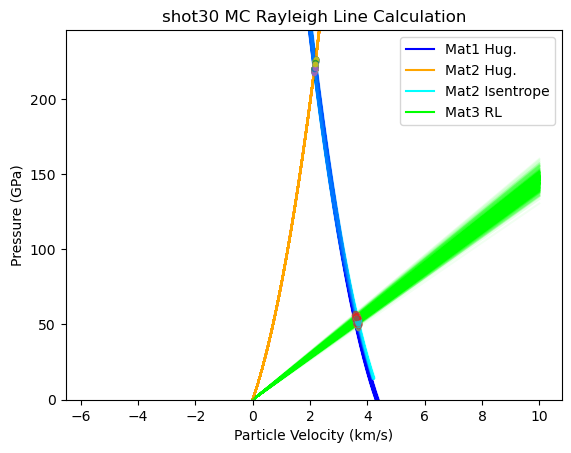

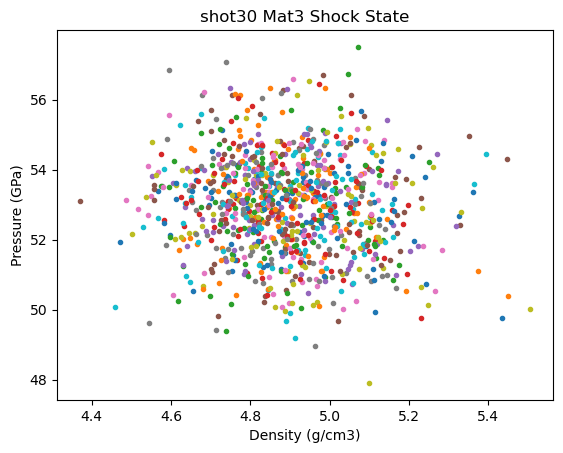

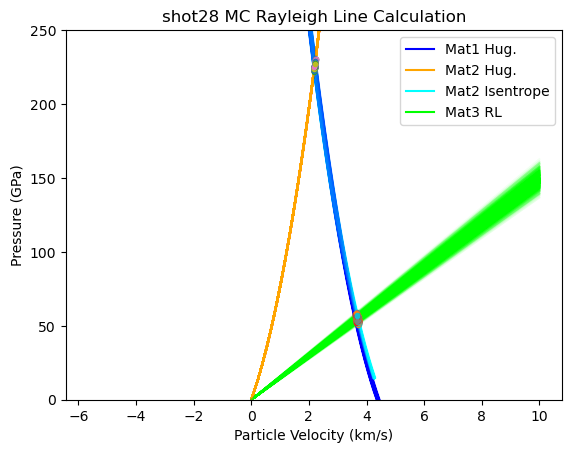

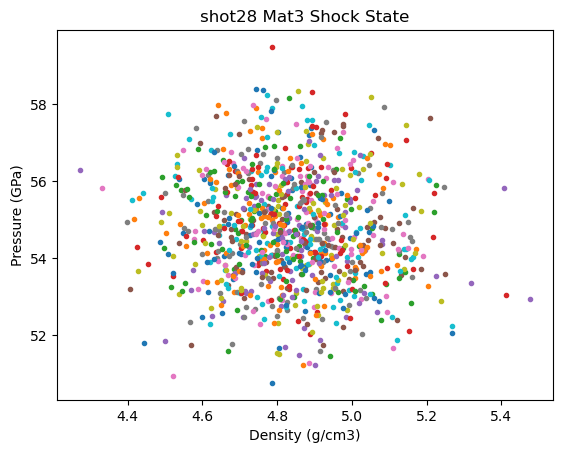

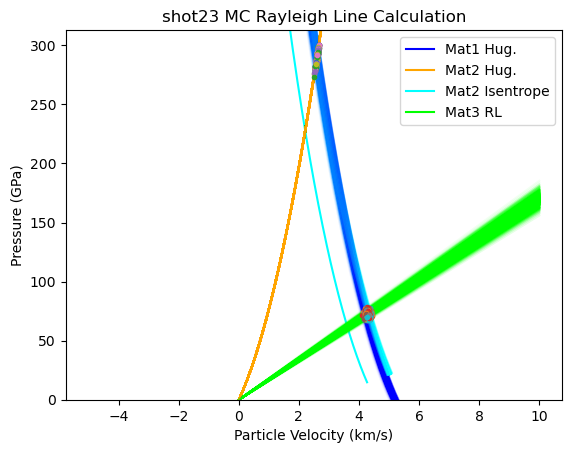

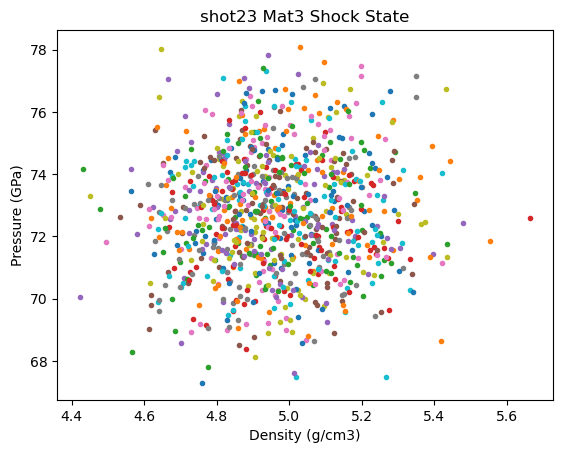

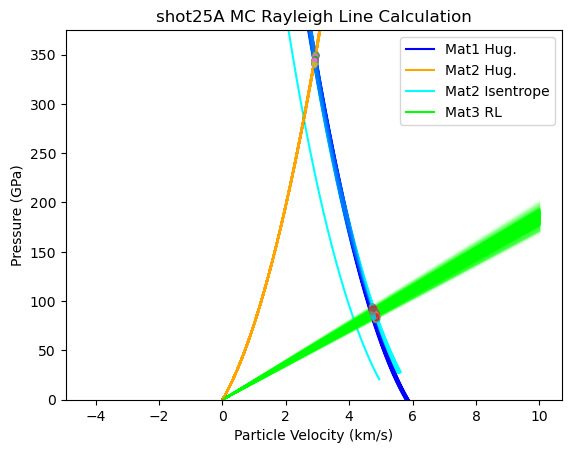

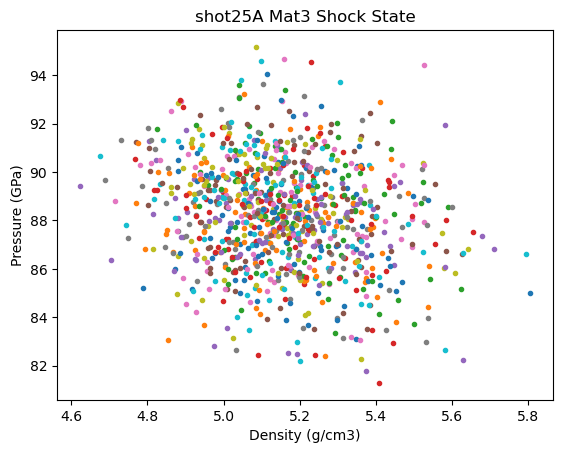

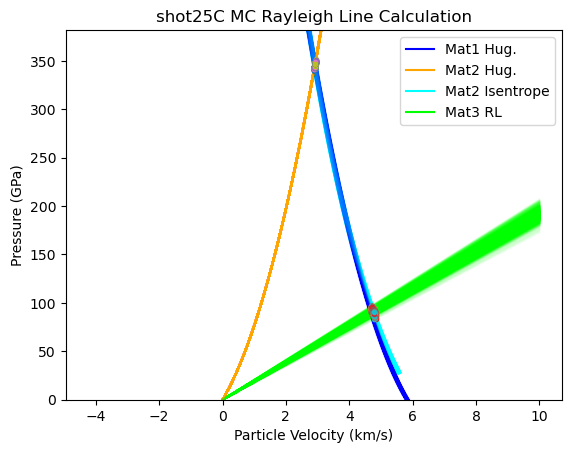

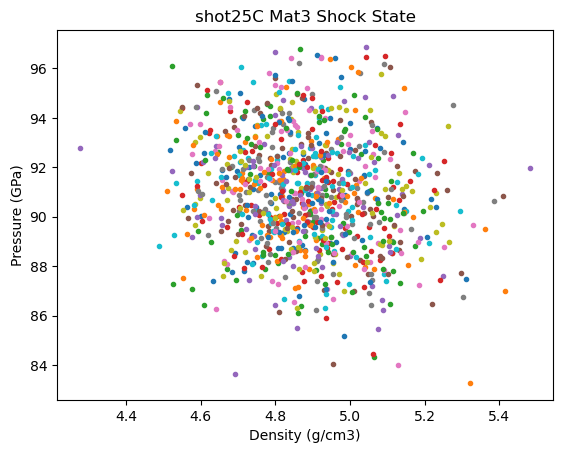

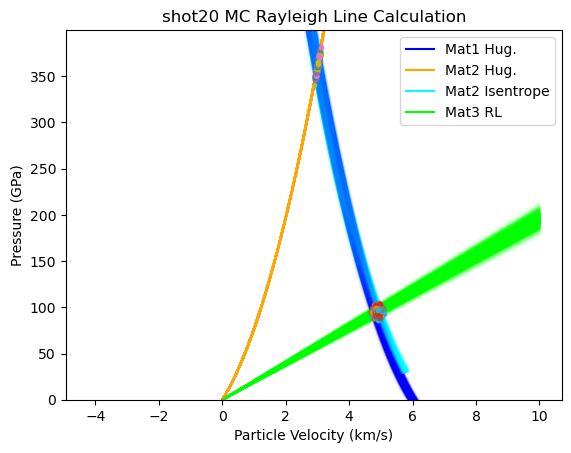

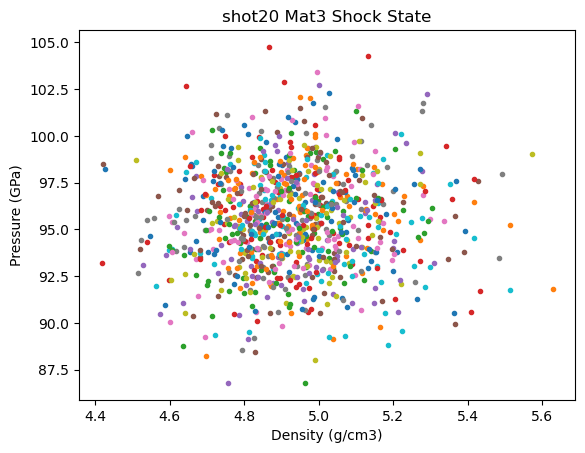

In [69]:
# write output in previous cell to text file
# unique file name for date and time to prevent over-writing output files
# datetime object containing current date and time
now = datetime.now()
#print("now =", now)
# YYmmdd-H-M-S
dt_string = now.strftime("%Y%m%d-%H%M%S")
print("date and time =", dt_string)
outputfilename = 'MCIM-Jackson-silica-output-'+dt_string+'.txt'
print('Output file name = '+outputfilename)

with open(outputfilename, 'w') as f:
    f.write(cap.stdout)

# The output in the previous cell is written to a text file and plot files
# print txt and images here for the notebook
cap.show()


## Plot the results

PDV + MAVIS gives impressively small error bars.

In [70]:
fs_list = []
fs_p_list = []
for i in range(len(jacksondata_list)):
    print(i,jacksondata_list[i].material[0],jacksondata_list[i].ref[0],jacksondata_list[i].P[0],jacksondata_list[i].P_std[0],jacksondata_list[i].up[0],jacksondata_list[i].up_std[0],jacksondata_list[i].rho[0],jacksondata_list[i].rho_std[0])
    fs_list.append(jacksondata_list[i])
    fs_p_list.append(jacksondata_list[i].P[0])



0 Fused Silica shot30 52.99217299148418 1.387559805876891 3.634234228439061 0.025384339990532048 4.8946046193206225 0.16500022906386083
1 Fused Silica shot28 54.75806239612898 1.3951153455075547 3.673645744094152 0.024168809207662213 4.8357431347806195 0.16680198630308535
2 Fused Silica shot23 72.75483288792216 1.8841198026010026 4.283852045500037 0.04732773823254176 4.961698732408732 0.18118986132546794
3 Fused Silica shot25A 88.23534347535337 2.2356282442818367 4.783507028868818 0.030939088151129234 5.155669644341244 0.18150376590401468
4 Fused Silica shot25C 90.96093367043804 2.2801497775315624 4.75435061756722 0.029783561756289885 4.879027796005978 0.16494275803406155
5 Fused Silica shot20 95.51963161729594 2.6569204520588263 4.89424234322018 0.05832232032602779 4.93130836311801 0.17564933094689217
